**Live Demo:** https://heart-disease-app-i4tmkghq8hhidzuauy9x6y.streamlit.app/      

# Heart Disease Prediction System

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) from four simple patient attributes.
##### **Application** Learning how a complete ML system is built, from data collection to cloud deployment. This is an educational demo, **not** a medical tool.
##### **Dataset** UCI Heart Disease dataset (Cleveland subset, `processed.cleveland.data`): https://archive.ics.uci.edu/dataset/45/heart+disease

## Input and Output

### Inputs (4 attributes selected from the dataset)

| **Input Attribute** | **Original column** | **Possible Values** |
| --- | --- | --- |
| **Sex** | `sex` | Male, Female |
| **ChestPain** | `cp` | Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic |
| **FastingBS** | `fbs` | Normal (<= 120 mg/dl), High (> 120 mg/dl) |
| **ExerciseAngina** | `exang` | No, Yes |

### Output

| **Output Attribute** | **Original column** | **Possible Values** |
| --- | --- | --- |
| **HeartDisease** | `num` | Yes (num 1 to 4), No (num 0) |

## Developer & System Information

| | |
| --- | --- |
| **Student Name / Reg. No** | ______________ |
| **Course** | AIC354 Machine Learning Fundamentals, COMSATS Lahore |
| **IDE** | Jupyter Notebook |
| **Libraries** | NumPy, Pandas, Pickle, scikit-learn, PrettyTable, Matplotlib, Seaborn |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding the Sample Data
- Step 6: Execute the Training Phase
- Step 7: Execute the Testing Phase
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deployment

### Step 1: Import Libraries

In [1]:
import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from prettytable import PrettyTable

import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

The UCI file `processed.cleveland.data` has no header row and uses `?` for missing values. It must be in the same folder as this notebook.

We read it, keep only **4 input attributes** (`sex`, `cp`, `fbs`, `exang`) and the output (`num`), and convert the numeric codes into readable category names. The result is saved as `sample-data.csv` and loaded back, exactly like the Titanic notebook.

In [2]:
# The 14 columns of processed.cleveland.data, in file order
raw_columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
               "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

raw_data = pd.read_csv("processed.cleveland.data", header=None, names=raw_columns, na_values="?")

# Keep only the 4 chosen inputs + the output, drop any row with a missing value
selected = raw_data[["sex", "cp", "fbs", "exang", "num"]].dropna().copy()

# Convert numeric codes into readable categories
sample_data = pd.DataFrame({
    "Sex": selected["sex"].map({0: "Female", 1: "Male"}),
    "ChestPain": selected["cp"].map({1: "Typical Angina", 2: "Atypical Angina",
                                     3: "Non-anginal Pain", 4: "Asymptomatic"}),
    "FastingBS": selected["fbs"].map({0: "Normal", 1: "High"}),
    "ExerciseAngina": selected["exang"].map({0: "No", 1: "Yes"}),
    "HeartDisease": (selected["num"] > 0).map({True: "Yes", False: "No"}),
})

sample_data.to_csv("sample-data.csv", index=False)

# Load the prepared data back
sample_data = pd.read_csv("sample-data.csv")

print("\n\nSample Data:")
print("============\n")
pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data)



Sample Data:

        Sex         ChestPain FastingBS ExerciseAngina HeartDisease
0      Male    Typical Angina      High             No           No
1      Male      Asymptomatic    Normal            Yes          Yes
2      Male      Asymptomatic    Normal            Yes          Yes
3      Male  Non-anginal Pain    Normal             No           No
4    Female   Atypical Angina    Normal             No           No
5      Male   Atypical Angina    Normal             No           No
6    Female      Asymptomatic    Normal             No          Yes
7    Female      Asymptomatic    Normal            Yes           No
8      Male      Asymptomatic    Normal             No          Yes
9      Male      Asymptomatic      High            Yes          Yes
10     Male      Asymptomatic    Normal             No           No
11   Female   Atypical Angina    Normal             No           No
12     Male  Non-anginal Pain      High            Yes          Yes
13     Male   Atypical Angina   

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(sample_data.columns)

print("\n\nNumber of Instances in Sample Data:", sample_data["Sex"].count())
print("========================================\n")

print("Output distribution:")
print(sample_data["HeartDisease"].value_counts())



Attributes in Sample Data:

Index(['Sex', 'ChestPain', 'FastingBS', 'ExerciseAngina', 'HeartDisease'], dtype='str')


Number of Instances in Sample Data: 303

Output distribution:
HeartDisease
No     164
Yes    139
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
- Rows with missing values (`?`) were dropped in Step 2. The 4 chosen attributes have no missing values, so no rows are lost.
- No other preprocessing is needed.

#### Step 4: Feature Extraction
- Only 4 attributes were selected from the 13 available (assignment constraint).
- The output `num` (0 to 4) was converted into a Yes/No label (0 = No, 1 to 4 = Yes).
- No further feature extraction is needed.

### Step 5: Label Encoding the Sample Data

#### Step 5.1: Train the Label Encoder

In [4]:
# All possible values of each attribute (not just the ones seen in the sample)
sex = pd.DataFrame({"Sex": ["Male", "Female"]})
chest_pain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"]})
fasting_bs = pd.DataFrame({"FastingBS": ["Normal", "High"]})
exercise_angina = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

sex_label_encoder = LabelEncoder()
chest_pain_label_encoder = LabelEncoder()
fasting_bs_label_encoder = LabelEncoder()
exercise_angina_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

sex_label_encoder.fit(np.ravel(sex))
chest_pain_label_encoder.fit(np.ravel(chest_pain))
fasting_bs_label_encoder.fit(np.ravel(fasting_bs))
exercise_angina_label_encoder.fit(np.ravel(exercise_angina))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

print("Sex:", list(sex_label_encoder.classes_))
print("ChestPain:", list(chest_pain_label_encoder.classes_))
print("FastingBS:", list(fasting_bs_label_encoder.classes_))
print("ExerciseAngina:", list(exercise_angina_label_encoder.classes_))
print("HeartDisease:", list(heart_disease_label_encoder.classes_))

Sex: ['Female', 'Male']
ChestPain: ['Asymptomatic', 'Atypical Angina', 'Non-anginal Pain', 'Typical Angina']
FastingBS: ['High', 'Normal']
ExerciseAngina: ['No', 'Yes']
HeartDisease: ['No', 'Yes']


#### Step 5.2: Label Encode the Output

In [5]:
original_sample_data = sample_data.copy()
sample_data_encoded_output = sample_data.copy()

sample_data_encoded_output["HeartDisease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])

print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
print(pd.DataFrame({"HeartDisease": sample_data["HeartDisease"],
                    "encoded": sample_data_encoded_output["HeartDisease"]}).head(10))

sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded
0           No        0
1          Yes        1
2          Yes        1
3           No        0
4           No        0
5           No        0
6          Yes        1
7           No        0
8          Yes        1
9          Yes        1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [6]:
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded["Sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded["ChestPain"] = chest_pain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded["FastingBS"] = fasting_bs_label_encoder.transform(sample_data_encoded_output["FastingBS"])
sample_data_encoded["ExerciseAngina"] = exercise_angina_label_encoder.transform(sample_data_encoded_output["ExerciseAngina"])

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)



Sample Data after Label Encoding:

     Sex  ChestPain  FastingBS  ExerciseAngina  HeartDisease
0      1          3          0               0             0
1      1          0          1               1             1
2      1          0          1               1             1
3      1          2          1               0             0
4      0          1          1               0             0
5      1          1          1               0             0
6      0          0          1               0             1
7      0          0          1               1             0
8      1          0          1               0             1
9      1          0          0               1             1
10     1          0          1               0             0
11     0          1          1               0             0
12     1          2          0               1             1
13     1          1          1               0             0
14     1          2          0               0  

### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [7]:
# 80% training, 20% testing. Rows are shuffled (random_state=0 keeps the split repeatable)
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=True
)

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (242, 5)
Testing Data shape: (61, 5)


#### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [8]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


#### Step 6.3: Train the Support Vector Classifier

In [9]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


#### Step 6.4: Save the Trained Model

In [10]:
pickle.dump(svc_model, open("heart_disease_svc_model.pkl", "wb"))
print("Saved: heart_disease_svc_model.pkl")

Saved: heart_disease_svc_model.pkl


### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [11]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


#### Step 7.2: Load the Saved Model

In [12]:
model = pickle.load(open("heart_disease_svc_model.pkl", "rb"))
print("Model loaded from heart_disease_svc_model.pkl")

Model loaded from heart_disease_svc_model.pkl


#### Step 7.3: Evaluate the Machine Learning Model

##### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [13]:
model_predictions = testing_data_encoded.copy()
model_predictions["Predictions"] = model.predict(input_vector_test)
model_predictions.to_csv("model-predictions.csv", index=False, header=True)

print("\n\nPredictions Returned by heart_disease_svc_model:")
print("================================================\n")
print(model_predictions)



Predictions Returned by heart_disease_svc_model:

     Sex  ChestPain  FastingBS  ExerciseAngina  HeartDisease  Predictions
225    0          1          1               0             0            0
152    0          2          1               0             0            0
228    1          0          1               1             1            1
201    0          0          1               1             0            1
52     1          0          1               0             1            1
245    1          0          1               0             1            1
175    1          0          1               1             1            1
168    1          0          1               1             1            1
223    1          0          1               1             1            1
217    0          0          1               1             0            1
111    1          0          0               1             1            1
135    0          1          1               0             0

#### Step 7.4: Calculate the Accuracy Score

In [14]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.75


#### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.76      0.83      0.79        35
   Heart Disease (1)       0.74      0.65      0.69        26

            accuracy                           0.75        61
           macro avg       0.75      0.74      0.74        61
        weighted avg       0.75      0.75      0.75        61


Confusion Matrix:

             Predicted: No  Predicted: Yes
Actual: No              29               6
Actual: Yes              9              17


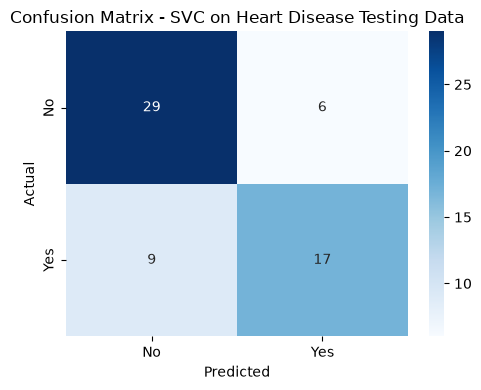

In [15]:
print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["HeartDisease"],
    model_predictions["Predictions"],
    target_names=["No Heart Disease (0)", "Heart Disease (1)"],
    zero_division=0
))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"], labels=[0, 1])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: No", "Actual: Yes"],
    columns=["Predicted: No", "Predicted: Yes"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout()
plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [16]:
# Demo patient (edit these values, or replace with input() calls)
sex_input = "Male"
chest_pain_input = "Asymptomatic"
fasting_bs_input = "Normal"
exercise_angina_input = "Yes"

print(f"Sex: {sex_input}, ChestPain: {chest_pain_input}, FastingBS: {fasting_bs_input}, ExerciseAngina: {exercise_angina_input}")

Sex: Male, ChestPain: Asymptomatic, FastingBS: Normal, ExerciseAngina: Yes


#### Step 8.2: Convert User Input into Feature Vector

In [17]:
user_input = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPain": [chest_pain_input],
    "FastingBS": [fasting_bs_input],
    "ExerciseAngina": [exercise_angina_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

    Sex     ChestPain FastingBS ExerciseAngina
0  Male  Asymptomatic    Normal            Yes


#### Step 8.3: Label Encoding of Feature Vector

In [18]:
unseen_data_features = user_input.copy()

unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["FastingBS"] = fasting_bs_label_encoder.transform(user_input["FastingBS"])
unseen_data_features["ExerciseAngina"] = exercise_angina_label_encoder.transform(user_input["ExerciseAngina"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   Sex  ChestPain  FastingBS  ExerciseAngina
0    1          0          1               1


#### Step 8.4: Load the Saved Model

In [19]:
model = pickle.load(open("heart_disease_svc_model.pkl", "rb"))

#### Step 8.5: Model Prediction

##### Step 8.5.1: Apply Model and Return Prediction to the User

In [20]:
predicted_disease = model.predict(unseen_data_features)[0]

if predicted_disease == 1:
    prediction = "HEART DISEASE LIKELY"
else:
    prediction = "NO HEART DISEASE LIKELY"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts

In [21]:
# Illustrative example only: this is sample feedback, not collected from real reviewers.
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Medical)", "Student Tester"],
    "Case": [
        "Male, asymptomatic chest pain, exercise angina -> HEART DISEASE LIKELY",
        "Female, atypical angina, no exercise angina -> NO HEART DISEASE LIKELY",
    ],
    "Feedback": [
        "Plausible: asymptomatic chest pain and exercise angina are linked to disease in this dataset.",
        "Plausible, but four attributes cannot capture risk factors like age, cholesterol or blood pressure.",
    ],
})
print(example_feedback.to_string(index=False))

               Reviewer                                                                   Case                                                                                            Feedback
Domain Expert (Medical) Male, asymptomatic chest pain, exercise angina -> HEART DISEASE LIKELY       Plausible: asymptomatic chest pain and exercise angina are linked to disease in this dataset.
         Student Tester Female, atypical angina, no exercise angina -> NO HEART DISEASE LIKELY Plausible, but four attributes cannot capture risk factors like age, cholesterol or blood pressure.


#### Step 9.2: Make a List of Potential Improvements

In [22]:
improvements = [
    "Add numeric attributes such as age, cholesterol and resting blood pressure",
    "Use more rows (combine the Cleveland, Hungarian and other UCI subsets)",
    "Use cross-validation and compare other models (Logistic Regression, Random Forest)",
    "Review the model with a medical domain expert before any real use",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add numeric attributes such as age, cholesterol and resting blood pressure
2. Use more rows (combine the Cleveland, Hungarian and other UCI subsets)
3. Use cross-validation and compare other models (Logistic Regression, Random Forest)
4. Review the model with a medical domain expert before any real use


#### Step 9.3: Improve the Model Based on Feedback

In [23]:
print("Next version: add more attributes, retrain, re-evaluate, then replace heart_disease_svc_model.pkl")

Next version: add more attributes, retrain, re-evaluate, then replace heart_disease_svc_model.pkl


### Step 10: Deployment

The trained model is deployed as a public Streamlit web app (`app.py`) on Streamlit Community Cloud. The live link is at the top of this notebook.

## Conclusion
A Support Vector Classifier was trained on four patient attributes from the UCI Heart Disease (Cleveland) dataset and deployed to the cloud. The model is for learning purposes only and must not be used for medical decisions.